# The Forge — Week 13

An autograd `Tensor` that records every operation performed on it, then walks that record backward
to hand each value its gradient. We write only the forward pass of each network below; the engine
supplies every backward pass.

Files: `tensor.py` (Parts 1–2, plus `tanh`/`sigmoid`), `optim.py` and `layers.py` (Part 3),
`train_mlp.py` (Part 4), `train_deep.py` (Part 5), `test_forge.py` (Part 6).

In [1]:
import os, platform, subprocess, sys, time

import numpy as np
import matplotlib.pyplot as plt

from tensor import Tensor
from layers import Linear, Sequential, Tanh, Sigmoid, MSELoss
from optim import SGD

%matplotlib inline

## Part 1 — The Autograd Tensor

Each `Tensor` made by an operation remembers its `creators` and `creation_op`, and each creator counts
the children it has. `backward` adds into `grad` with `+=` (fix a) and only passes the gradient on once
every child has reported (fix b).

**Value used twice.** `b` feeds both `d` and `e`, so its two contributions must add up to 2.

In [2]:
a = Tensor([1, 2, 3, 4, 5], autograd=True)
b = Tensor([2, 2, 2, 2, 2], autograd=True)
c = Tensor([5, 4, 3, 2, 1], autograd=True)
d = a + b; e = b + c; f = d + e
f.backward(Tensor(np.array([1, 1, 1, 1, 1])))
print("b.grad:", b.grad.data, "  (expected [2 2 2 2 2])")

b.grad: [2 2 2 2 2]   (expected [2 2 2 2 2])


**The wait.** `s` is made by an operation and used twice, so it must collect both gradients before
passing them to `x`. An engine that does not wait raises `cannot backprop more than once` here.

In [3]:
x = Tensor([1, 2, 3, 4, 5], autograd=True)
y = Tensor([1, 1, 1, 1, 1], autograd=True)
s = x + y
loss = (s + a) + (s + c)
loss.backward(Tensor(np.array([1, 1, 1, 1, 1])))
print("x.grad:", x.grad.data, "  (expected [2 2 2 2 2])")

x.grad: [2 2 2 2 2]   (expected [2 2 2 2 2])


## Part 2 — The Operation Table

Every operation is a forward paired with a backward branch:

| op | forward | backward (gradient handed to creators) |
|---|---|---|
| `neg` | −a | negate the gradient |
| `sub` | a − b | grad to a; negated grad to b |
| `mul` | a ⊙ b | grad ⊙ b to a; grad ⊙ a to b |
| `mm` | a b | grad·bᵀ to a; aᵀ·grad to b |
| `transpose` | aᵀ | transpose the gradient |
| `sum(dim)` | collapse dim | expand the gradient back along dim |
| `expand(dim, n)` | copy along a new dim | sum the gradient back over dim |

**Re-use through `mm`.** `h` is made by an `mm` and then used twice. An `mm` branch that forgets to
pass `self` as `grad_origin` prints `[[12.0, 40.0], [18.0, 60.0]]` instead.

In [4]:
X = Tensor([[1., 2.], [3., 4.]], autograd=True)
W = Tensor([[0.5, -0.5], [1., 0.25]], autograd=True)
A = Tensor([[1., 0.], [2., 1.]], autograd=True)
B = Tensor([[0., 1.], [1., 3.]], autograd=True)
h = X.mm(W)
(h.mm(A) + h.mm(B)).sum(0).sum(0).backward()
print("W.grad:", W.grad.data.tolist(), "  (expected [[8.0, 28.0], [12.0, 42.0]])")

W.grad: [[8.0, 28.0], [12.0, 42.0]]   (expected [[8.0, 28.0], [12.0, 42.0]])


**`sum` and `expand` are duals.** The backward of `sum` is `expand`, and vice versa.

In [5]:
v = Tensor(np.array([[1., 2., 3.], [4., 5., 6.]]), autograd=True)
v.sum(0).backward(Tensor(np.array([1., 10., 100.])))
print("sum(0) backward  ->", v.grad.data.tolist())

u = Tensor(np.array([1., 2.]), autograd=True)
u.expand(0, 3).backward(Tensor(np.ones((3, 2))))
print("expand(0,3) backward ->", u.grad.data.tolist(), " (each value was copied 3 times)")

sum(0) backward  -> [[1.0, 10.0, 100.0], [1.0, 10.0, 100.0]]
expand(0,3) backward -> [3.0, 3.0]  (each value was copied 3 times)


## Part 3 — The Optimizer and the Layers

`SGD.step()` does `p.data -= p.grad.data * alpha` for every parameter and then zeroes the gradient,
because `backward` accumulates. `Linear` owns a weight and a bias; `Sequential` chains layers and
gathers every sub-layer's parameters for the optimizer.

In [6]:
net = Sequential([Linear(2, 3), Tanh(), Linear(3, 1), Sigmoid()])
params = net.get_parameters()
print("parameters:", len(params), "->", [p.data.shape for p in params])

parameters: 4 -> [(2, 3), (3,), (3, 1), (1,)]


## Part 4 — Train the MLP

Each run seeds with `np.random.seed(0)` and builds `data` and `target` right after the seed, before
any weights, so the numbers match the handout. `data` and `target` carry `autograd=True`: an
operation records its result only when both operands are in the graph.

Two runs: the **bare MLP** (two explicit weight tensors, `alpha=0.1`) and the same shape of net as a
**`Sequential`** of two `Linear` layers (`alpha=0.01`). Neither has a hand-written backward pass.

In [7]:
def make_data():
    data = Tensor([[0, 0], [0, 1], [1, 0], [1, 1]], autograd=True)
    target = Tensor([[0], [1], [0], [1]], autograd=True)
    return data, target

def plot_curve(losses, title):
    plt.figure(figsize=(5, 3))
    plt.plot(range(len(losses)), losses, marker="o")
    plt.xlabel("iteration"); plt.ylabel("loss"); plt.title(title)
    plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

results = {}

iter 0: loss 0.5813
iter 1: loss 0.4899
iter 2: loss 0.4138
iter 3: loss 0.3449
iter 4: loss 0.2821
iter 5: loss 0.2254
iter 6: loss 0.1754
iter 7: loss 0.1324
iter 8: loss 0.0968
iter 9: loss 0.0685


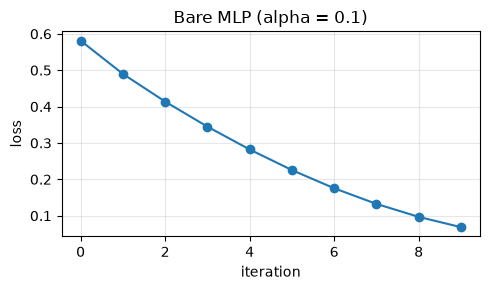

In [8]:
# Bare MLP: two weight tensors, manual SGD step.
np.random.seed(0)
data, target = make_data()
w = [Tensor(np.random.rand(2, 3), autograd=True),
     Tensor(np.random.rand(3, 1), autograd=True)]

bare_losses, t0 = [], time.perf_counter()
for i in range(10):
    pred = data.mm(w[0]).mm(w[1])
    loss = ((pred - target) * (pred - target)).sum(0)
    loss.backward()
    for w_ in w:
        w_.data -= w_.grad.data * 0.1
        w_.grad.data *= 0
    bare_losses.append(float(loss.data[0]))
    print(f"iter {i}: loss {bare_losses[-1]:.4f}")
results["Bare MLP (alpha=0.1)"] = (bare_losses, time.perf_counter() - t0)
plot_curve(bare_losses, "Bare MLP (alpha = 0.1)")

iter 0: loss 2.3343
iter 1: loss 1.5092
iter 2: loss 0.9845
iter 3: loss 0.6478
iter 4: loss 0.4317
iter 5: loss 0.2933
iter 6: loss 0.2050
iter 7: loss 0.1488
iter 8: loss 0.1128
iter 9: loss 0.0897


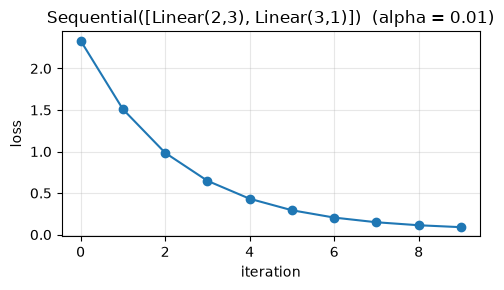

In [9]:
# The same net as a Sequential of two Linear layers.
np.random.seed(0)
data, target = make_data()
model = Sequential([Linear(2, 3), Linear(3, 1)])
optim = SGD(parameters=model.get_parameters(), alpha=0.01)

seq_losses, t0 = [], time.perf_counter()
for i in range(10):
    pred = model.forward(data)
    loss = ((pred - target) * (pred - target)).sum(0)
    loss.backward()
    optim.step()
    seq_losses.append(float(loss.data[0]))
    print(f"iter {i}: loss {seq_losses[-1]:.4f}")
results["Sequential MLP (alpha=0.01)"] = (seq_losses, time.perf_counter() - t0)
plot_curve(seq_losses, "Sequential([Linear(2,3), Linear(3,1)])  (alpha = 0.01)")

The handout expects the bare MLP to go ≈ 0.5813 → 0.0685 and the `Sequential` MLP ≈ 2.334 → 0.0897.
They differ because `Linear` initializes with a scaled `randn` and adds a bias. Both fall at every step.

## Part 5 — Add the Bend

Two stacked `Linear` layers are still linear. Adding `Tanh` and `Sigmoid` makes a real nonlinear net.
The only gradient code it needs are the two backward branches in `tensor.py`:
`tanh → grad·(1 − out²)` and `sigmoid → grad·out·(1 − out)`. `MSELoss` sums the squared error over
the batch.

iter 0: loss 1.0637


iter 1: loss 0.7515
iter 2: loss 0.5738
iter 3: loss 0.3957
iter 4: loss 0.2482
iter 5: loss 0.1552
iter 6: loss 0.1042
iter 7: loss 0.0757
iter 8: loss 0.0584
iter 9: loss 0.0470


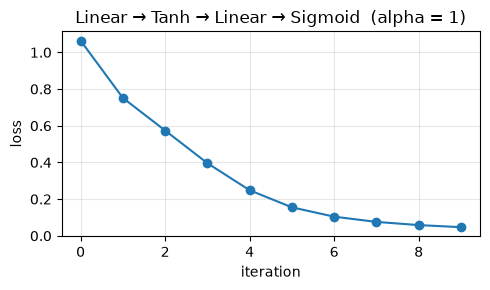

In [10]:
np.random.seed(0)
data, target = make_data()
model = Sequential([Linear(2, 3), Tanh(), Linear(3, 1), Sigmoid()])
criterion = MSELoss()
optim = SGD(parameters=model.get_parameters(), alpha=1)

deep_losses, t0 = [], time.perf_counter()
for i in range(10):
    pred = model.forward(data)
    loss = criterion.forward(pred, target)
    loss.backward()
    optim.step()
    deep_losses.append(float(loss.data[0]))
    print(f"iter {i}: loss {deep_losses[-1]:.4f}")
results["Nonlinear net (alpha=1)"] = (deep_losses, time.perf_counter() - t0)
plot_curve(deep_losses, "Linear → Tanh → Linear → Sigmoid  (alpha = 1)")

The handout expects ≈ 1.064 → 0.047.

**All three curves together** (log scale):

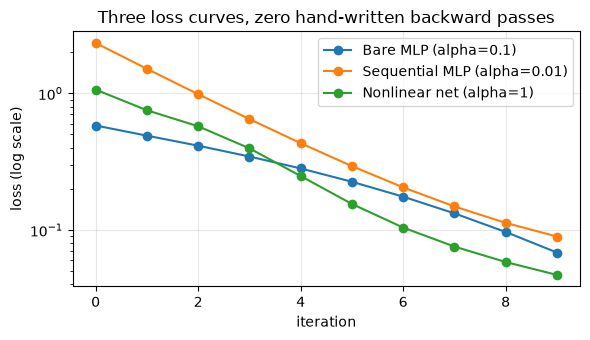

In [11]:
plt.figure(figsize=(6, 3.5))
for name, (losses, _) in results.items():
    plt.plot(range(len(losses)), losses, marker="o", label=name)
plt.yscale("log"); plt.xlabel("iteration"); plt.ylabel("loss (log scale)")
plt.title("Three loss curves, zero hand-written backward passes")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Part 6 — Tests, Including a Gradient Check

A numeric gradient check nudges an input by ±ε, re-runs the forward pass, and asks whether the
analytic gradient predicted the change: (f(x+ε) − f(x−ε)) / 2ε. A missing or wrong backward branch on
the path makes the check fail.

**Check 1: `y = Σ x²`.** Runs through the `mul` and `sum` branches only.

In [12]:
eps = 1e-5
x = Tensor([2.0, 3.0], autograd=True)
(x * x).sum(0).backward()
analytic = x.grad.data.copy()

f = lambda v: np.sum(v * v)
numeric = np.array([(f(x.data + eps * e) - f(x.data - eps * e)) / (2 * eps)
                    for e in np.eye(len(x.data))])

print("analytic:", analytic)
print("numeric: ", numeric)
print(f"max |analytic - numeric| = {np.max(np.abs(analytic - numeric)):.2e}  (must be < 1e-4)")

analytic: [4. 6.]
numeric:  [4. 6.]
max |analytic - numeric| = 3.93e-11  (must be < 1e-4)


**Check 2: the whole Part 5 network.** Nudge one entry of the first layer's weight and recompute the
loss with a fresh forward pass. This single path runs through `mm`, `add`, `expand`, `tanh`,
`sigmoid`, `sub`, `mul` and `sum` at once.

In [13]:
np.random.seed(0)
data, target = make_data()
model = Sequential([Linear(2, 3), Tanh(), Linear(3, 1), Sigmoid()])
criterion = MSELoss()
weight = model.layers[0].weight

criterion.forward(model.forward(data), target).backward()

def loss_value():
    d, t = make_data()  # fresh tensors so the check doesn't touch the graph above
    return float(criterion.forward(model.forward(d), t).data[0])

rows = []
for (r, c_) in [(0, 0), (0, 1), (1, 2)]:
    original = weight.data[r, c_]
    weight.data[r, c_] = original + eps; up = loss_value()
    weight.data[r, c_] = original - eps; down = loss_value()
    weight.data[r, c_] = original
    rows.append((r, c_, weight.grad.data[r, c_], (up - down) / (2 * eps)))

print(f"{'entry':>8} {'analytic':>14} {'numeric':>14} {'|diff|':>10}")
for r, c_, an, nu in rows:
    print(f"{str((r, c_)):>8} {an:14.8f} {nu:14.8f} {abs(an - nu):10.2e}")
print(f"max |analytic - numeric| = {max(abs(an - nu) for *_, an, nu in rows):.2e}  (must be < 1e-4)")

   entry       analytic        numeric     |diff|
  (0, 0)    -0.01228883    -0.01228883   9.61e-12
  (0, 1)    -0.03547342    -0.03547342   9.95e-12
  (1, 2)    -0.02807226    -0.02807226   1.23e-11
max |analytic - numeric| = 1.23e-11  (must be < 1e-4)


**The full test suite** (`test_forge.py`, eight tests).

In [14]:
if os.path.exists("test_forge.py"):
    out = subprocess.run([sys.executable, "test_forge.py"], capture_output=True, text=True)
    print(out.stdout or out.stderr)
else:
    print("test_forge.py is not in this folder yet; it lands with the Part 6 PR.")

RUNNING THE FORGE UNIT TEST SUITE
[PASS] Multi-use gradient accumulation
[PASS] Addition passes gradients
[PASS] Numeric gradient check
[PASS] Sequential model learns
[PASS] Nonlinear model parameters
[PASS] Shared intermediate gradients
[PASS] Matrix multiplication gradient
[PASS] Whole network gradient check
------------------------------------------------------------
Results: 8/8 tests passed.



## Summary

In [15]:
print(f"{'run':<30} {'start':>8} {'final':>8} {'time (ms)':>10}")
for name, (losses, secs) in results.items():
    print(f"{name:<30} {losses[0]:8.4f} {losses[-1]:8.4f} {secs * 1000:10.1f}")
print()
print("Every curve fell at every step:",
      all(all(b < a for a, b in zip(l, l[1:])) for l, _ in results.values()))
print("Hardware:", platform.processor() or platform.machine(), "|", platform.system(), platform.release(),
      "| Python", platform.python_version(), "| NumPy", np.__version__)

run                               start    final  time (ms)
Bare MLP (alpha=0.1)             0.5813   0.0685        1.9
Sequential MLP (alpha=0.01)      2.3343   0.0897        2.7
Nonlinear net (alpha=1)          1.0637   0.0470        3.1

Every curve fell at every step: True
Hardware: AMD64 Family 25 Model 33 Stepping 2, AuthenticAMD | Windows 11 | Python 3.13.15 | NumPy 2.5.2


## Holocron — Reading

In our autograd framework, implementing a forward operation without its backward branch breaks the chain rule at that exact node. If we deleted the mm (matrix multiplication) backward branch in tensor.py, the forward pass would execute normally without raising any errors or warnings. The network would still compute predictions and produce a loss value. However, during loss.backward(), the gradient propagation would hit the mm node and silently stop. Because mm never calls .backward() on its creators (input and self.weight), every upstream weight and bias parameter feeding into that layer would keep grad = None. In our framework, optim.step() would immediately crash with an AttributeError when trying to access p.grad.data; if guarded against None, those weights would simply never update, leaving the model frozen and incapable of learning.

This is precisely the trap Vex fell into: keeping the forward "power" to generate outputs while stripping away the backward "price" that allows errors to correct the system. To catch this defect before shipping, we rely on numeric gradient checking (using central differences to verify that analytic gradients match numerical perturbations) paired with mandatory PR reviews verifying that every forward operation has a complete backward counterpart.